# Sounds, spectra and trigonometric sums

*A companion notebook to* **Prime Numbers and the Riemann Hypothesis** *by Barry Mazur and William Stein (Cambridge University Press, 2016), Part I, chapters "What do computer music files, data compression, and prime numbers have to do with each other?", "The word 'Spectrum'" and "Spectra and trigonometric sums".*

The second half of the book's story is about **spectra**: the idea that a complicated signal can be taken apart into pure waves, and that the list of their frequencies (the spectrum) can say everything about it. The book introduces the idea with sound, and then asks whether the staircase of primes has a spectrum. In this notebook you will play with pure tones and chords, recover a sound's spectrum from samples (which is how music files are compressed), and build a sawtooth wave from its spectrum.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
t = var('t')

## 1. A pure tone

> The very purest of sounds—a single sustained note—would look something like this (called a "sine wave") …

A pure tone is $f(t) = a\cos(b + \theta t)$. In the book's words, the *amplitude* $a$ "corresponds to the *loudness* of the sound", and the *frequency* $\theta$ "corresponds to the *pitch* of the sound"; $b$ is the *phase*, which shifts the wave in time.

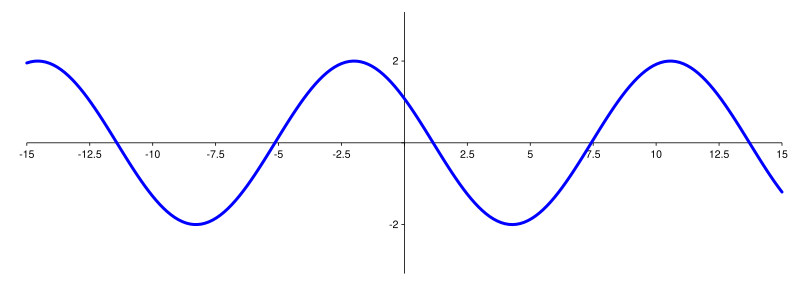

In [2]:
@interact
def pure_tone(a=slider(0.5, 3, 0.1, 2, label='amplitude a'),
              theta=slider(0.1, 3, 0.05, 0.5, label='frequency theta'),
              b=slider(0, 6.3, 0.1, 1, label='phase b')):
    show(plot(a * cos(b + theta * t), (t, -15, 15), thickness=2), ymin=-3.2, ymax=3.2, figsize=[8, 3])

## 2. A chord, and its five numbers

> A next most simple example of a sound would be a simple chord (say a C and an E played together on some electronic instrument that could approximate pure notes). Its graph would be just the *sum* of the graphs of each of the pure notes.

The notes C and E have frequencies in the ratio $329.63 : 261.63$. Delay the E (its phase) and change its loudness:

> So, *all you need* to reconstruct the chord graphed above is to know five numbers:
> * the two frequencies—the collection of frequencies that make up the sound is called the *spectrum* of the sound,
> * the two *amplitudes* of each of these two frequencies,
> * the *phase* between them.

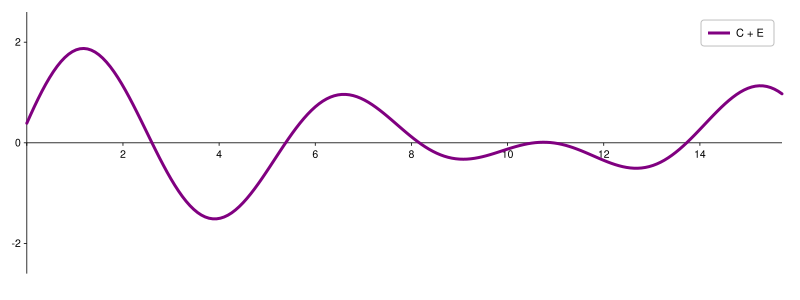

In [3]:
E_OVER_C = 329.63 / 261.63

@interact
def chord(phase=slider(0, 6.3, 0.1, 0.4, label='phase of the E'),
          loud=slider(0, 1.5, 0.05, 1, label='amplitude of the E'),
          separate=checkbox(False, label='show the two notes separately')):
    c, e = sin(t), loud * sin(E_OVER_C * t + phase)
    if separate:
        g = plot(c, (t, 0, 5 * pi), color='blue', legend_label='C') + plot(e, (t, 0, 5 * pi), color='red', legend_label='E')
    else:
        g = plot(c + e, (t, 0, 5 * pi), color='purple', thickness=2, legend_label='C + E')
    show(g, ymin=-2.6, ymax=2.6, figsize=[8, 3])

## 3. Recording a sound: samples, or its spectrum?

> Now suppose you came across such a sound … and wanted to "record it." Well, one way would be to sample the amplitude of the sound at many different times … But this sampling would take an enormous amount of storage space, at least compared to storing five numbers …

The **Fourier transform** turns samples back into a spectrum. Below, a sound made of three pure tones is sampled; the fast Fourier transform (`np.fft`) of the samples shows a "blip" at each tone's frequency, with height its amplitude. Those few blips are all a compressed file needs to keep.

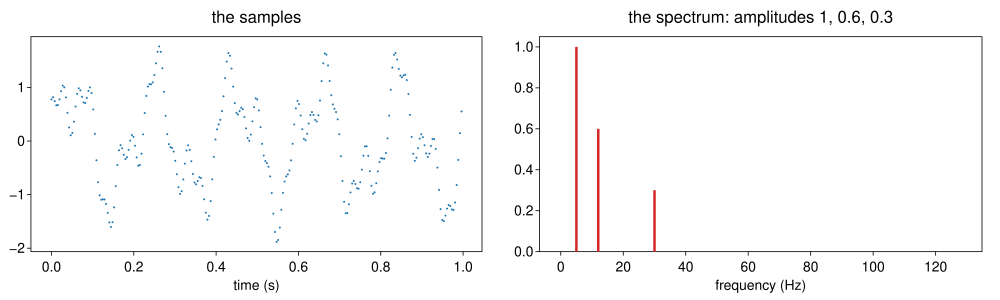

In [4]:
@interact
def recover_the_spectrum(f1=slider(1, 40, 1, 5, label='frequency 1 (Hz)'),
                         f2=slider(1, 40, 1, 12, label='frequency 2 (Hz)'),
                         f3=slider(1, 40, 1, 30, label='frequency 3 (Hz)'),
                         noise=slider(0, 1, 0.05, 0, label='noise')):
    rate = 256                                   # samples per second, for one second
    s = np.arange(rate) / rate
    rng = np.random.default_rng(0)
    sound = 1.0 * np.sin(2 * np.pi * f1 * s) + 0.6 * np.sin(2 * np.pi * f2 * s + 1) + 0.3 * np.sin(2 * np.pi * f3 * s + 2)
    sound += noise * rng.standard_normal(rate)
    spectrum = np.abs(np.fft.rfft(sound)) * 2 / rate
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3))
    left.plot(s, sound, '.', markersize=2)
    left.set_title('the samples')
    left.set_xlabel('time (s)')
    right.bar(np.arange(len(spectrum)), spectrum, width=0.8, color='tab:red')
    right.set_title('the spectrum: amplitudes 1, 0.6, 0.3')
    right.set_xlabel('frequency (Hz)')
    plt.show()

## 4. Trigonometric sums and their spectra

> Sometimes we encounter functions $F(t)$ that are not pure tones, but that can be expressed as (or we might say "decomposed into") a finite sum of pure tones, for example three of them:
$$F(t) = a_1\cos(b_1 +\theta_1 t) + a_2\cos(b_2 +\theta_2 t) + a_3\cos(b_3 +\theta_3 t)$$
> … we say that *the spectrum of $F(t)$* is the set of these frequencies, i.e., $\{\theta_1,\theta_2,\theta_3\}$.

The book's example is $5\cos(-t - 2) + 2\cos(t/2 + 1) + 3\cos(2t + 4)$, with spectrum $\{1, \tfrac12, 2\}$ (as frequencies, $\cos(-t-2) = \cos(t+2)$). Change the amplitudes and watch the graph and its spectrum together.

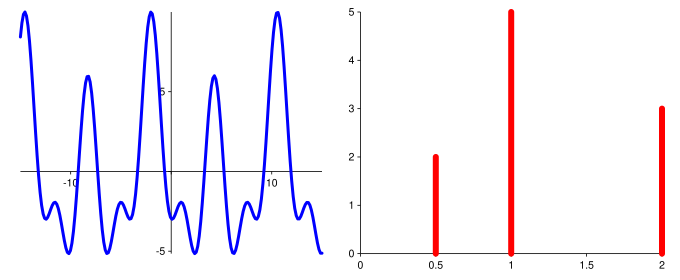

In [5]:
@interact
def trig_sum(a1=slider(0, 6, 0.5, 5, label='amplitude at 1'),
             a2=slider(0, 6, 0.5, 2, label='amplitude at 1/2'),
             a3=slider(0, 6, 0.5, 3, label='amplitude at 2')):
    F = a1 * cos(-t - 2) + a2 * cos(t / 2 + 1) + a3 * cos(2 * t + 4)
    graph = plot(F, (t, -15, 15), thickness=2)
    spectrum = sum(line([(theta, 0), (theta, a)], thickness=4, color='red') for theta, a in [(1, a1), (1/2, a2), (2, a3)])
    show(graphics_array([graph, spectrum + point((0, 0), size=0)]), figsize=[10, 3])

## 5. A sawtooth from its spectrum

Infinite trigonometric sums can make shapes no single wave suggests. The sawtooth wave, which climbs from $0$ to $1$ and drops back at every whole number, is
$$\operatorname{saw}(t) = \frac12 - \frac1\pi \sum_{k=1}^{\infty} \frac{\sin(2\pi k t)}{k},$$
so its spectrum is the frequencies $1, 2, 3, \dots$ (times $2\pi$) with amplitudes $\frac{1}{\pi k}$: the book draws it as a spike of height $1/k$ at each $k$. Add terms and watch the partial sums approach the sawtooth. (The overshoot near the jumps, which never goes away, is the Gibbs phenomenon.)

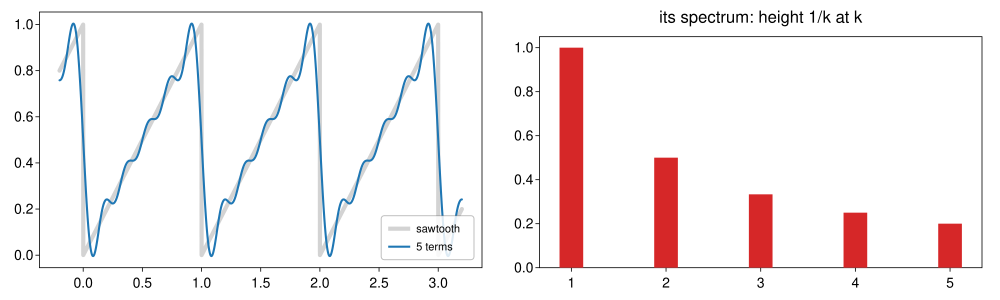

In [6]:
@interact
def sawtooth(terms=slider(1, 60, 1, 5, label='terms of the sum')):
    s = np.linspace(-0.2, 3.2, 3000)
    partial = 0.5 - sum(np.sin(2 * np.pi * k * s) / k for k in range(1, terms + 1)) / np.pi
    saw = s - np.floor(s)
    fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3), gridspec_kw={'width_ratios': [2, 1]})
    left.plot(s, saw, color='lightgray', linewidth=3, label='sawtooth')
    left.plot(s, partial, color='tab:blue', label='%d terms' % terms)
    left.legend(loc='lower right')
    k = np.arange(1, terms + 1)
    right.bar(k, 1 / k, width=0.25, color='tab:red')
    right.set_title('its spectrum: height 1/k at k')
    plt.show()

## 6. Does the staircase of primes have a spectrum?

The book then asks the questions that lead to the Riemann Hypothesis:

> * Is there a way of using Fourier analysis to better understand the complicated picture of the staircase of primes?
> * Does this staircase of primes (or, perhaps, some tinkered version of the staircase that contains the same basic information) have a *spectrum*?
> * If such a *spectrum* exists, can we compute it conveniently, just as we have done for the saw-tooth wave above, or for the major third CE chord?
> * Assuming the spectrum exists, and is computable, will our understanding of this spectrum allow us to reproduce all the pertinent information about the placement of primes among all whole numbers, elegantly and faithfully?
> * And here is a most important question: will that spectrum show us order and organization lurking within the staircase that we would otherwise be blind to?

The answer, in the next notebook, is yes: the spectrum is the list of numbers $\theta_1 = 14.13\ldots$, $\theta_2 = 21.02\ldots$, … where $\tfrac12 + i\theta_k$ are the zeros of $\zeta(s)$ (the **Riemann spectrum**), and the Riemann Hypothesis is what makes it a spectrum in this sense.

## Things to try

1. In section 3, set two frequencies equal. What does the spectrum show? Now add noise: at what noise level can you no longer read off the three tones?
2. In section 5, how far above $1$ does the partial sum overshoot near a jump with $60$ terms? With $600$? (Gibbs: about $9\%$ of the jump, forever.)
3. A square wave has spectrum $\frac{4}{\pi k}$ at odd $k$ only. Change the sawtooth cell to build it.

---
*Adapted and greatly expanded from the code that drew the figures in* Prime Numbers and the Riemann Hypothesis *(Barry Mazur and William Stein, Cambridge University Press, 2016); quotations are from the book. MIT license. Runs in the browser with [Sagebrush](https://sagebrush.space).*